# **Assignment 2**


**Anja Pijak**  
ap72051@student.uni-lj.si


In [71]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
import warnings
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.utils import resample
warnings.filterwarnings("ignore", category=FutureWarning)

#### Data preparation


In [ ]:
column_names = [
    "state", "county", "community", "communityname", "fold", "population", "householdsize",
    "racepctblack", "racePctWhite", "racePctAsian", "racePctHisp", "agePct12t21", "agePct12t29",
    "agePct16t24", "agePct65up", "numbUrban", "pctUrban", "medIncome", "pctWWage", "pctWFarmSelf",
    "pctWInvInc", "pctWSocSec", "pctWPubAsst", "pctWRetire", "medFamInc", "perCapInc", "whitePerCap",
    "blackPerCap", "indianPerCap", "AsianPerCap", "OtherPerCap", "HispPerCap", "NumUnderPov", 
    "PctPopUnderPov", "PctLess9thGrade", "PctNotHSGrad", "PctBSorMore", "PctUnemployed", 
    "PctEmploy", "PctEmplManu", "PctEmplProfServ", "PctOccupManu", "PctOccupMgmtProf", 
    "MalePctDivorce", "MalePctNevMarr", "FemalePctDiv", "TotalPctDiv", "PersPerFam", "PctFam2Par", 
    "PctKids2Par", "PctYoungKids2Par", "PctTeen2Par", "PctWorkMomYoungKids", "PctWorkMom", "NumIlleg", 
    "PctIlleg", "NumImmig", "PctImmigRecent", "PctImmigRec5", "PctImmigRec8", "PctImmigRec10", 
    "PctRecentImmig", "PctRecImmig5", "PctRecImmig8", "PctRecImmig10", "PctSpeakEnglOnly", 
    "PctNotSpeakEnglWell", "PctLargHouseFam", "PctLargHouseOccup", "PersPerOccupHous", 
    "PersPerOwnOccHous", "PersPerRentOccHous", "PctPersOwnOccup", "PctPersDenseHous", "PctHousLess3BR", 
    "MedNumBR", "HousVacant", "PctHousOccup", "PctHousOwnOcc", "PctVacantBoarded", "PctVacMore6Mos", 
    "MedYrHousBuilt", "PctHousNoPhone", "PctWOFullPlumb", "OwnOccLowQuart", "OwnOccMedVal", 
    "OwnOccHiQuart", "RentLowQ", "RentMedian", "RentHighQ", "MedRent", "MedRentPctHousInc", 
    "MedOwnCostPctInc", "MedOwnCostPctIncNoMtg", "NumInShelters", "NumStreet", "PctForeignBorn", 
    "PctBornSameState", "PctSameHouse85", "PctSameCity85", "PctSameState85", "LemasSwornFT", 
    "LemasSwFTPerPop", "LemasSwFTFieldOps", "LemasSwFTFieldPerPop", "LemasTotalReq", "LemasTotReqPerPop", 
    "PolicReqPerOffic", "PolicPerPop", "RacialMatchCommPol", "PctPolicWhite", "PctPolicBlack", 
    "PctPolicHisp", "PctPolicAsian", "PctPolicMinor", "OfficAssgnDrugUnits", "NumKindsDrugsSeiz", 
    "PolicAveOTWorked", "LandArea", "PopDens", "PctUsePubTrans", "PolicCars", "PolicOperBudg", 
    "LemasPctPolicOnPatr", "LemasGangUnitDeploy", "LemasPctOfficDrugUn", "PolicBudgPerPop", 
    "ViolentCrimesPerPop"
]


df = pd.read_csv("datasets/communities.data", names = column_names)

df.head()

# drop the first 5 columns (from assignment guidelines)
df = df.iloc[:, 5:]

# droping columns which are mostly na (from communities.names info)
# all of these have 1675 na rows out of (1994)
na_cols = ["LemasSwornFT", 
    "LemasSwFTPerPop", "LemasSwFTFieldOps", "LemasSwFTFieldPerPop", "LemasTotalReq", "LemasTotReqPerPop", 
    "PolicReqPerOffic", "PolicPerPop", "RacialMatchCommPol", "PctPolicWhite", "PctPolicBlack", 
    "PctPolicHisp", "PctPolicAsian", "PctPolicMinor", "OfficAssgnDrugUnits", "NumKindsDrugsSeiz", 
    "PolicAveOTWorked", "PolicCars", "PolicOperBudg", 
    "LemasPctPolicOnPatr", "LemasGangUnitDeploy", "PolicBudgPerPop"]
df = df.drop(columns=na_cols)

# replace ? with na
df.replace('?', np.nan, inplace=True)
# converting all columns in the df to numeric
df = df.apply(pd.to_numeric)
# fill na with average value
df.fillna(df.mean(), inplace=True)

df.head()



,population,householdsize,racepctblack,racePctWhite,racePctAsian,racePctHisp,agePct12t21,agePct12t29,agePct16t24,agePct65up,...,PctForeignBorn,PctBornSameState,PctSameHouse85,PctSameCity85,PctSameState85,LandArea,PopDens,PctUsePubTrans,LemasPctOfficDrugUn,ViolentCrimesPerPop
0,0.19,0.33,0.02,0.90,0.12,0.17,0.34,0.47,0.29,0.32,...,0.12,0.42,0.50,0.51,0.64,0.12,0.26,0.20,0.32,0.20
1,0.00,0.16,0.12,0.74,0.45,0.07,0.26,0.59,0.35,0.27,...,0.21,0.50,0.34,0.60,0.52,0.02,0.12,0.45,0.00,0.67
2,0.00,0.42,0.49,0.56,0.17,0.04,0.39,0.47,0.28,0.32,...,0.14,0.49,0.54,0.67,0.56,0.01,0.21,0.02,0.00,0.43
3,0.04,0.77,1.00,0.08,0.12,0.10,0.51,0.50,0.34,0.21,...,0.19,0.30,0.73,0.64,0.65,0.02,0.39,0.28,0.00,0.12
4,0.01,0.55,0.02,0.95,0.09,0.05,0.38,0.38,0.23,0.36,...,0.11,0.72,0.64,0.61,0.53,0.04,0.09,0.02,0.00,0.03


#### Cross validation

In [ ]:
def cross_validate(data, n):
    # shuffle data
    data = data.sample(frac=1, random_state=42).reset_index(drop=True)

    chunks = np.array_split(data, n) # split data into n chunks
    scores = []
    # create a list of chunks of data and save it as folds
    folds = {}
    for i, chunk in enumerate(chunks):
        folds[f"chunk_{i+1}"] = chunk 

    for i in range(n):
        test_fold = folds[f"chunk_{i + 1}"] # use current fold for test
        # remaining chunks for training
        train_folds = pd.concat([folds[f"chunk_{j + 1}"] for j in range(n) if j != i])

        # split into x and y (attributes and target)
        x_train = train_folds.loc[:, train_folds.columns != 'ViolentCrimesPerPop']
        y_train = train_folds['ViolentCrimesPerPop'] 
        x_test = test_fold.loc[:, test_fold.columns != 'ViolentCrimesPerPop']
        y_test = test_fold['ViolentCrimesPerPop'] 
        
        model = LinearRegression()
        model.fit(x_train, y_train)
        predictions = model.predict(x_test)

        # store all predictions in the list
        score = mean_squared_error(y_test, predictions)
        scores.append(score)
    

    return scores    # return all scores


Testing on the whole dataset, to see if it works.

In [ ]:
n = 5 # 5-fold cross validation
scores = cross_validate(df, n) 
print(scores)

print(np.mean(scores))


[0.017343639121717786, 0.016576177064309604, 0.024178201103463942, 0.01630874161605784, 0.019544257358341737]
0.018790203252778186


#### Leave one out


In [ ]:
def leave_one_out(data):
    # shuffle data
    data = data.sample(frac=1, random_state=42).reset_index(drop=True)

    n = data.shape[0] # number of rows
    scores = [] 

    for i in range(n):
        test = data[i:i+1] # test is the i-th row
        train = data.drop(index=i) # train are all other rows

        x_train = train.loc[:, train.columns != 'ViolentCrimesPerPop']
        y_train = train['ViolentCrimesPerPop'] 
        x_test = test.loc[:, test.columns != 'ViolentCrimesPerPop']
        y_test = test['ViolentCrimesPerPop'] 

        model = LinearRegression()
        model.fit(x_train, y_train)
        predictions = model.predict(x_test)

        score = mean_squared_error(y_test, predictions)
        scores.append(score)
    
    return scores

Again, testing on the whole dataset to check if it works.

In [43]:
scores_loo = leave_one_out(df) 
print(np.mean(scores_loo))


0.01852320616831318


#### Forward Attribute Selection

This function uses my implementation of cross fold

In [ ]:
def forward_selection(data):    
    remaining_features = set(data.columns) - {'ViolentCrimesPerPop'} # at the begining take all features, exclude ViolentCrimesPerPop cuz it's target
    selected_features = []
    best_score = float('inf') # best score is infinity in the begining 

    while remaining_features:
        scores_with_candidates = []
        for candidate in remaining_features:
            temp_features = selected_features + [candidate] # add current candidate to selected features, then test theur  performance 
            score = np.mean(cross_validate(data[temp_features + ['ViolentCrimesPerPop']], 5)) # score is avg of mse found in cross fold
            scores_with_candidates.append((score, candidate)) # add the score of current candidate

        # sort scores and select the best candidate
        scores_with_candidates.sort()
        best_new_score, best_candidate = scores_with_candidates[0]

        # if the new best score is actually better then the previous (there is imrpovement) add feature to selected
        if best_new_score < best_score:
            selected_features.append(best_candidate)
            remaining_features.remove(best_candidate)
            best_score = best_new_score  # update best score
            print(f"Iteration {len(selected_features)}: Added feature '{best_candidate}' with MSE: {best_score}")
        else:
            print(f"Stopping: MSE started to increase. Best MSE: {best_score}")
            break  # no improvement -> stop


    return selected_features


Run this algorithm on whole dataset and save the selected features

In [ ]:
df = df.sample(frac=1, random_state=42).reset_index(drop=True)
# no x,y just splitting the whole df because x,y calculated in the method
train_data, test_data = train_test_split(df, test_size=0.3, random_state=42) 

selected_features = forward_selection(train_data)
print(selected_features)

Iteration 1: Added feature 'PctKids2Par' with MSE: 0.025763085552555444
Iteration 2: Added feature 'racePctWhite' with MSE: 0.02265591550208818
Iteration 3: Added feature 'HousVacant' with MSE: 0.021191557568123357
Iteration 4: Added feature 'pctUrban' with MSE: 0.02079302205981271
Iteration 5: Added feature 'PctWorkMom' with MSE: 0.020485062741744796
Iteration 6: Added feature 'MalePctDivorce' with MSE: 0.020216074723316248
Iteration 7: Added feature 'PctIlleg' with MSE: 0.019905762391218697
Iteration 8: Added feature 'PctPersDenseHous' with MSE: 0.019767152282119966
Iteration 9: Added feature 'PctHousOccup' with MSE: 0.019627416850926557
Iteration 10: Added feature 'agePct12t29' with MSE: 0.01954073255960419
Iteration 11: Added feature 'LemasPctOfficDrugUn' with MSE: 0.01946908089772368
Iteration 12: Added feature 'MedOwnCostPctIncNoMtg' with MSE: 0.019397557612036265
Iteration 13: Added feature 'NumStreet' with MSE: 0.01933440625705215
Iteration 14: Added feature 'racepctblack' with

Check if MSE improved before and after selecting features.

We see in the results below that MSE improved when we filtered the attributes.

In [ ]:
# train_data and test_data is calculated in previous code chunk
# here have to calculate x and y because we use built in lin. regression and not my methods
X_train = train_data.loc[:, train_data.columns != 'ViolentCrimesPerPop']
X_test = test_data.loc[:, test_data.columns != 'ViolentCrimesPerPop']
y_train, y_test = train_data['ViolentCrimesPerPop'], test_data['ViolentCrimesPerPop']

# first test linear regression when all features are there, as a baseline
model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
score = mean_squared_error(y_test, y_pred)
print("MSE before selecting features: ",score)

# test linear regression with selected features
model.fit(X_train[selected_features], y_train)

y_pred1 = model.predict(X_test[selected_features])
score1 = mean_squared_error(y_test, y_pred1)
print("MSE after selecting features: ",score1)

MSE before selecting features:  0.018033065752111502
MSE after selecting features:  0.017282889342170697


#### Bootstrap

In [80]:
bootstrap_scores = []

X_train = train_data[selected_features]
y_train = train_data['ViolentCrimesPerPop']
X_test = test_data[selected_features]
y_test = test_data['ViolentCrimesPerPop']

# train 1000 different linear models
for i in range(1000):
    X_bootstrap, y_bootstrap = resample(X_train, y_train, replace=True) # generate sample for ith iteration
    model = LinearRegression()
    model.fit(X_bootstrap, y_bootstrap)
    predictions = model.predict(X_test)
    mse = mean_squared_error(y_test, predictions)
    bootstrap_scores.append(mse)

# confidence intervals and mean
lower_ci = np.percentile(bootstrap_scores, 2.5)
upper_ci = np.percentile(bootstrap_scores, 97.5)
mean_mse = np.mean(bootstrap_scores)

print(f"Mean MSE: {mean_mse}")
print(f"95% Confidence Interval: ({lower_ci}, {upper_ci})")


Mean MSE: 0.017844128735466383
95% Confidence Interval: (0.01713593971849161, 0.01872228735176198)


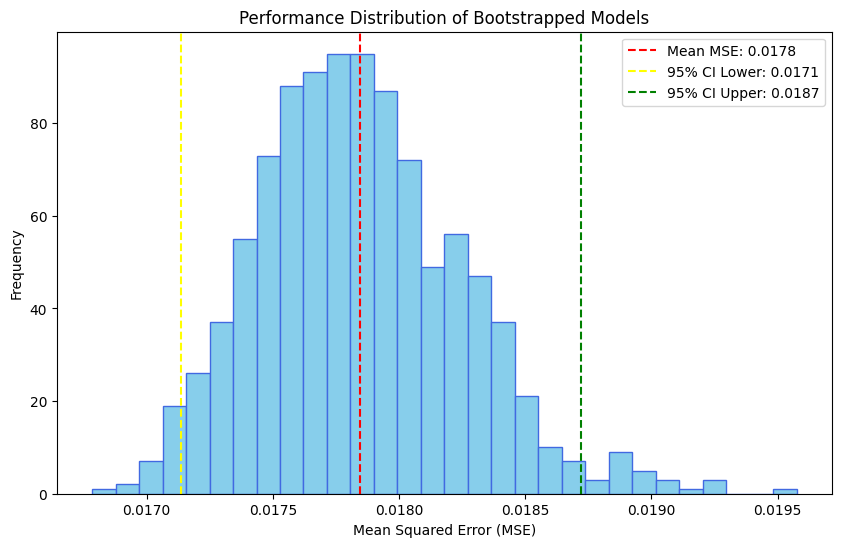

In [81]:
plt.figure(figsize=(10, 6))
plt.hist(bootstrap_scores, bins=30, color='skyblue', edgecolor='royalblue')
plt.axvline(mean_mse, color='red', linestyle='--', label=f'Mean MSE: {mean_mse:.4f}')
plt.axvline(lower_ci, color='yellow', linestyle='--', label=f'95% CI Lower: {lower_ci:.4f}')
plt.axvline(upper_ci, color='green', linestyle='--', label=f'95% CI Upper: {upper_ci:.4f}')
plt.xlabel('Mean Squared Error (MSE)')
plt.ylabel('Frequency')
plt.title('Performance Distribution of Bootstrapped Models')
plt.legend()
plt.show()